# Job 51280737 — does SHAPE matter at a fixed parameter budget?

Stages E, H and I closed the width axis at `L=12`: attention-only `d256` (E2)
is the standing minimum at `rho_50` 0.605, `d192` is already in the barrier
band at 0.754, `d160` is 0.773, and `d128` does not train on 2 of 3 seeds. Each
of those cuts changed SIZE, and size moved the metric. The question left is
whether the same number of parameters, **arranged differently**, is worth
anything.

Stage J asks it directly with two rungs built to the same budget:

| arm | architecture | trainable | rho_50 | crossing | escapes |
|---|---|---|---|---|---|
| J1 | attention-only `L=12 d224` | 2,571,130 | 0.579 | 3/3 | 3/3 |
| J2 | attention-only `L=16 d192` | 2,504,890 | 0.580 | 3/3 | 3/3 |

**They are indistinguishable: 0.001 apart, 0.00 `s*`.** The budgets came back
2.6% apart against the 5% tolerance that would have VOIDED the contrast, so
this is a controlled comparison and not a size verdict wearing a hat. The
falsifier named a winner in advance in either direction — DEPTH or WIDTH — and
neither fired.

Two consequences, and they point in opposite directions:

* **J2 HELD and J3 FIRED.** `L=16 d192` sits 0.174 (1.18 `s*`) below `H2`, the
  same width at `L=12`, so depth past 12 still pays at N=48 — the first
  leak-free point above `L=12` on this problem. It clears the standing-minimum
  rule at 3 of 3, and the minimum moves from **E2, 3,331,642 @ 0.605** to
  **J2, 2,504,890 @ 0.580**.
* **J1 MISSED LOW.** All three registered interpolations (0.680 / 0.685 /
  0.669) are falsified in the same direction, so the width curve is **convex**
  on [192, 256] and interpolating `d_model` between measured rungs
  systematically underestimates the in-between model.

Everything below is scored by `scripts/stagej_score.py`, committed (`88cb7cb`)
while `51280737` was still in its first wave. This notebook runs it; it does not
restate its conclusions in its own words. Section 6 gives `rho_50` before and
after against the previous best on the same eval.

In [1]:
import json, os, subprocess, sys
sys.path.insert(0, "/home/users/hshunt/spin_gnn")
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt

REPO = "/home/users/hshunt/spin_gnn"
BOOT = 2000          # the programme's scoring default; CIs here match the scorers'
SEEDS = (0, 1, 2)    # both arms are 3 seeds

from scripts.minarch_analysis import SCAN_DIRS, SCAN_E, SCAN_G, SCAN_H, SCAN_I, SCAN_J
from scripts.stagec_score import HUB, PLATEAU, S_RHO50, S_MEAN, escapes, rho_txt, rung, summarize
from scripts.stagej_score import (BAND_HI, BAND_LO, DEPTH_EVIDENCE, E2, FREE, H1, H2,
                                  HUB_RHO50, HUB_TRAINABLE, I1, J1, J2, LOO_BAR,
                                  MATCH_AT_REGISTRATION, MATCH_TOL, PRED_J1_HI,
                                  PRED_J1_INTERP, PRED_J1_LO, PRED_J2_BELOW,
                                  PREDICTED_TRAINABLE, STANDING)
from notebooks.make_stagej_deck import FULL_L12, collect, curve, frontier_rows, pair, sufficiency

# SCAN_J is read here and HAS to be -- it is the subject. It stays out of
# SCAN_DIRS, and so out of the pooled s*, because its rungs would otherwise
# enter the yardstick that stages A-F were already scored against. s* is quoted
# frozen below and never recomputed.
DIRS = SCAN_DIRS + [SCAN_E, SCAN_G, SCAN_H, SCAN_I, SCAN_J]

COMMIT = subprocess.run(["git", "rev-parse", "--short", "HEAD"], cwd=REPO,
                        capture_output=True, text=True).stdout.strip()
print("git commit        ", COMMIT)
print("branch            ", subprocess.run(["git", "rev-parse", "--abbrev-ref", "HEAD"],
                                           cwd=REPO, capture_output=True,
                                           text=True).stdout.strip())
print("scorer registered ", "88cb7cb, while 51280737 was in its first wave")
print("bootstrap draws   ", BOOT)
print("frozen yardstick  ", f"s* = {S_RHO50} in rho_50, {S_MEAN} in mean_solve")
print("plateau           ", f"train NLL {PLATEAU} (finding 44, an N=48 number)")
print("free line         ", f"rho_50 <= {FREE} (hub {HUB_RHO50} + s*)")
print("matched-budget tol", f"{MATCH_TOL:.0%} -- above this the contrast is VOID, not reported")
print("sufficiency bar   ", f"leave-one-out RMS {LOO_BAR}")
print("scan dirs         ", len(DIRS), "dirs; the subject is", os.path.basename(SCAN_J))

git commit         217d052
branch             sudoku-dd
scorer registered  88cb7cb, while 51280737 was in its first wave
bootstrap draws    2000
frozen yardstick   s* = 0.1484 in rho_50, 0.2918 in mean_solve
plateau            train NLL 1.64 (finding 44, an N=48 number)
free line          rho_50 <= 0.74 (hub 0.592 + s*)
matched-budget tol 5% -- above this the contrast is VOID, not reported
sufficiency bar    leave-one-out RMS 0.0423
scan dirs          9 dirs; the subject is sudoku_n48_minarch_J_2026-11-05


## 1. Provenance: two knobs on purpose, and the budget that justifies it

Every other comparison in this programme moves ONE field. Stage J moves two —
`num_layers` 12→16 and `d_model` 224→192 — because that is the only way to hold
the parameter count still while changing the shape. So the provenance check is
different in kind:

1. **nothing else may differ.** Read off each cell's `config.json`, not the
   sbatch headers: same pool, same epochs, same lr and schedule, same
   `dim_feedforward`, same `nhead`, same `arch_mode`, same `--shuffle-adj
   --fall` task.
2. **the budgets must actually match.** `4*d^2 + 8*d` per layer plus
   `630*d + 58` fixed was registered in the sbatch as an assertion that aborts
   before training if the model it builds disagrees. The registered counts are
   2,571,130 and 2,504,890, 2.6% apart, and the registration says a realized
   mismatch above 5% VOIDS the contrast rather than reporting it.

If either check fails the whole page is a size comparison in disguise.

In [2]:
cells, raw = collect(DIRS, BOOT)
p = pair(cells)
p["J1"]["name_short"], p["J2"]["name_short"] = "L=12 d224", "L=16 d192"
print(f"{len(cells)} cells on disk | "
      + " | ".join(f"{t} {p[t]['s']['n']}/3 seeds" for t in ("J1", "J2")) + chr(10))

FIELDS = ("num_layers", "d_model", "dim_feedforward", "nhead", "arch_mode", "epochs",
          "lr", "lr_schedule", "batch_size", "n_train_instances", "warmup_epochs",
          "shuffle_adj", "fall", "n_nodes", "degree", "n_colors")
print(f"{'arm':<26}" + "".join(f"{f.replace('_', ' ')[:11]:>13}" for f in FIELDS[:5]))
print("-" * 91)
base = None
for t in ("J1", "J2"):
    cfg = json.load(open(os.path.join(p[t]["ms"][0]["path"], "config.json")))
    print(f"{t + '  attention-only ' + p[t]['name_short']:<26}"
          + "".join(f"{str(cfg.get(f)):>13}" for f in FIELDS[:5]))
    base = base or cfg

print()
print("THE TWO KNOBS THAT MAY MOVE: num_layers and d_model. Everything else, per cell:")
for t in ("J1", "J2"):
    for m in p[t]["ms"]:
        a = json.load(open(os.path.join(m["path"], "config.json")))
        # solve_metrics, baseline_accuracy and n_trainable_params are written
        # back into config.json by the runner -- outputs of the cell, not inputs.
        diff = sorted(k for k in set(a) | set(base) if a.get(k) != base.get(k)
                      and k not in ("out_dir", "run_name", "seed", "num_layers", "d_model",
                                    "solve_metrics", "baseline_accuracy",
                                    "n_trainable_params"))
        print(f"  {t} seed {a['seed']}: fields differing besides num_layers, d_model "
              f"and seed: {diff or 'NONE'}")
print()
print("held constant across all 6 cells:",
      "  ".join(f"{f}={base.get(f)}" for f in FIELDS[5:]))

print()
print("THE MATCHED BUDGET -- registered formula vs what the models actually built")
print(f"  {'arm':<8}{'predicted':>12}{'observed':>12}   formula 4*d^2+8*d per layer, 630*d+58 fixed")
print("  " + "-" * 76)
tr = {}
for t in ("J1", "J2"):
    L, d = p[t]["key"][0], p[t]["key"][3]
    want = PREDICTED_TRAINABLE[t]
    assert want == L * (4 * d * d + 8 * d) + 630 * d + 58, "formula disagrees with registration"
    tr[t] = got = p[t]["s"]["trainable"]
    print(f"  {t:<8}{want:>12,}{got:>12,}   {'ok' if want == got else 'MISMATCH'}"
          f"   (registered in the sbatch)")
mismatch = abs(tr["J1"] - tr["J2"]) / ((tr["J1"] + tr["J2"]) / 2)
print(f"  realized mismatch {mismatch:.1%} against the {MATCH_TOL:.0%} tolerance -- "
      f"{'CONTROLLED' if mismatch <= MATCH_TOL else 'VOID'}")
print(f"  (registered at {MATCH_AT_REGISTRATION:.1%} from the formula, before either arm ran)")

99 cells on disk | J1 3/3 seeds | J2 3/3 seeds

arm                          num layers      d model  dim feedfor        nhead    arch mode
-------------------------------------------------------------------------------------------
J1  attention-only L=12 d224           12          224         1024            4       no_mlp
J2  attention-only L=16 d192           16          192         1024            4       no_mlp

THE TWO KNOBS THAT MAY MOVE: num_layers and d_model. Everything else, per cell:
  J1 seed 0: fields differing besides num_layers, d_model and seed: NONE
  J1 seed 1: fields differing besides num_layers, d_model and seed: NONE
  J1 seed 2: fields differing besides num_layers, d_model and seed: NONE
  J2 seed 0: fields differing besides num_layers, d_model and seed: NONE
  J2 seed 1: fields differing besides num_layers, d_model and seed: NONE
  J2 seed 2: fields differing besides num_layers, d_model and seed: NONE

held constant across all 6 cells: epochs=50  lr=0.001  lr_sc

## 2. The metrics table

`rho_50` is the realized hint density at which the solve rate crosses 0.5 on a
14-point × 400-instance leak-free grid (`--shuffle-adj --fall`), **lower is
better**, reported CENSORED when no bin crosses. `mean_solve` is the unweighted
mean over the 14 bins and never censors. `spread` is the seed-to-seed range in
`mean_solve`, against the frozen bar `s*` = 0.2918 on that metric.

Medians are compared to medians, three seeds per arm. The seed spread is the
thing to read against the arm-to-arm difference: if the spread swamps the gap,
there is no gap to report, and that is exactly what happened here.

In [3]:
print(f"  {'arm':<28}{'rho_50':>10}{'mean_solve':>12}{'spread':>9}{'cross':>8}{'esc':>6}"
      f"{'tok acc':>10}{'train NLL':>11}{'trainable':>12}")
print("  " + "-" * 106)
for t in ("J1", "J2"):
    s, r = p[t]["s"], p[t]
    print(f"  {t + '  no_mlp ' + r['name_short']:<28}{rho_txt(s):>10}"
          f"{s['mean_solve']:>12.4f}{s['spread_mean']:>9.4f}{s['n_cross']:>5}/{s['n']}"
          f"{r['esc']:>4}/{s['n']}{r['acc']:>10.4f}{sorted(r['nll'])[1]:>11.4f}"
          f"{s['trainable']:>12,}")

print()
print("  per-seed rho_50 and final train NLL")
for t in ("J1", "J2"):
    # rung() returns the cells already ordered by seed; the seed itself lives in
    # the cell's config.json, not in the metrics dict.
    sd = [json.load(open(os.path.join(m["path"], "config.json")))["seed"] for m in p[t]["ms"]]
    per = ", ".join(f"s{i} " + (f"{m['rho50']:.3f}" if m["flag"] == "ok" else "CENSORED")
                    for i, m in zip(sd, p[t]["ms"]))
    nll = "  ".join(f"{v:.4f}{'*' if v < PLATEAU else ' '}" for v in p[t]["nll"])
    print(f"    {t}  rho_50 {per}")
    print(f"    {t}  NLL    {nll}   (* = below the {PLATEAU} plateau)")

print()
gap = p["J1"]["s"]["rho50"] - p["J2"]["s"]["rho50"]
sprd = max(p[t]["s"]["spread_mean"] for t in ("J1", "J2"))
print(f"  THE CONTRAST: |J1 - J2| = {abs(gap):.3f} in rho_50 = {abs(gap) / S_RHO50:.2f} s*")
print(f"  separable at this bar? {'YES' if abs(gap) > S_RHO50 else 'NO'}")
print(f"  for scale, the larger of the two seed spreads in mean_solve is {sprd:.4f},")
print(f"  and the arm-to-arm difference in mean_solve is "
      f"{abs(p['J1']['s']['mean_solve'] - p['J2']['s']['mean_solve']):.4f} -- "
      f"inside its own seed noise.")

  arm                             rho_50  mean_solve   spread   cross   esc   tok acc  train NLL   trainable
  ----------------------------------------------------------------------------------------------------------
  J1  no_mlp L=12 d224             0.579      0.5521   0.2970    3/3   3/3    0.4948     1.5359   2,571,130
  J2  no_mlp L=16 d192             0.580      0.5527   0.2586    3/3   3/3    0.4940     1.5356   2,504,890

  per-seed rho_50 and final train NLL
    J1  rho_50 s0 0.579, s1 0.771, s2 0.549
    J1  NLL    1.5359*  1.5499*  1.5269*   (* = below the 1.64 plateau)
    J2  rho_50 s0 0.580, s1 0.557, s2 0.752
    J2  NLL    1.5356*  1.5261*  1.5494*   (* = below the 1.64 plateau)

  THE CONTRAST: |J1 - J2| = 0.001 in rho_50 = 0.00 s*
  separable at this bar? NO
  for scale, the larger of the two seed spreads in mean_solve is 0.2970,
  and the arm-to-arm difference in mean_solve is 0.0005 -- inside its own seed noise.


## 3. The registered scorer, run verbatim

`scripts/stagej_score.py` was committed (`88cb7cb`) while `51280737` was in its
first wave, before any of the six cells had an eval on disk, so no verdict here
was chosen after seeing a number. It is run as a subprocess so the words in this
notebook and on the slides can be checked against the words the scorer prints.

It carries two controls worth naming. **J1's interpolations were registered in
three forms** — linear in `d`, linear in trainable parameters, linear in `1/d` —
so a miss cannot be re-read as "the other interpolation was the right one".
**J3's tie-break was named in advance** as "take the smaller parameter count",
precisely so that a tie between two qualifying rungs could not be broken
afterwards on whichever metric happened to favour one.

In [4]:
r = subprocess.run([sys.executable, "-m", "scripts.stagej_score"], cwd=REPO,
                   capture_output=True, text=True)
print("=" * 100)
print("$ python3 -m scripts.stagej_score")
print("=" * 100)
print(r.stdout)
if r.returncode != 0:
    print("STDERR:", r.stderr[-2000:])

$ python3 -m scripts.stagej_score
STAGE J: at a matched parameter count, does SHAPE matter?
  93 cells read; TWO rungs 2.6% apart in trainable params
  frozen bar s* = 0.1484 rho_50 / 0.2918 mean_solve, NOT recomputed
  registered: J0 |J1 - J2| <= s*; J1 in [0.665, 0.690]; J2 below 0.754

FROZEN-LITERAL CONTROL (the L=12 width ladder, re-read from disk):
  H1 matches the frozen literals
  I1 matches the frozen literals
  H2 matches the frozen literals
  E2 matches the frozen literals

=== J1 -- no_mlp L=12 d224, the wide-shallow arm ===
  3/3 seeds on disk, 3/3 crossed 0.5
  rho_50 median     0.579   (hub 0.592, E2 0.605, H2 0.754, free at or below 0.74)
  mean_solve       0.5521   [spread 0.2970]
  trainable 2,571,130   (header arithmetic 2,571,130)
  plateau escapes 3/3   final train NLL 1.5359/1.5499/1.5269

=== J2 -- no_mlp L=16 d192, the deep-narrow arm ===
  3/3 seeds on disk, 3/3 crossed 0.5
  rho_50 median     0.580   (hub 0.592, E2 0.605, H2 0.754, free at or below 0.74)
  mea

## 4. The figures, as they appear on the slides

Drawn by importing the deck module, so the notebook and the PDF cannot drift.

The first is the whole result in one panel: every seed of both arms, their
median bars 0.001 apart, the `s*` scale bar beside them for size, plus the six
solve-rate curves the `rho_50` is read off and the six training curves. The
second is the size–quality frontier: every attention-only rung this programme
has run at N=48, against the two complete-model anchors, on a log parameter
axis.

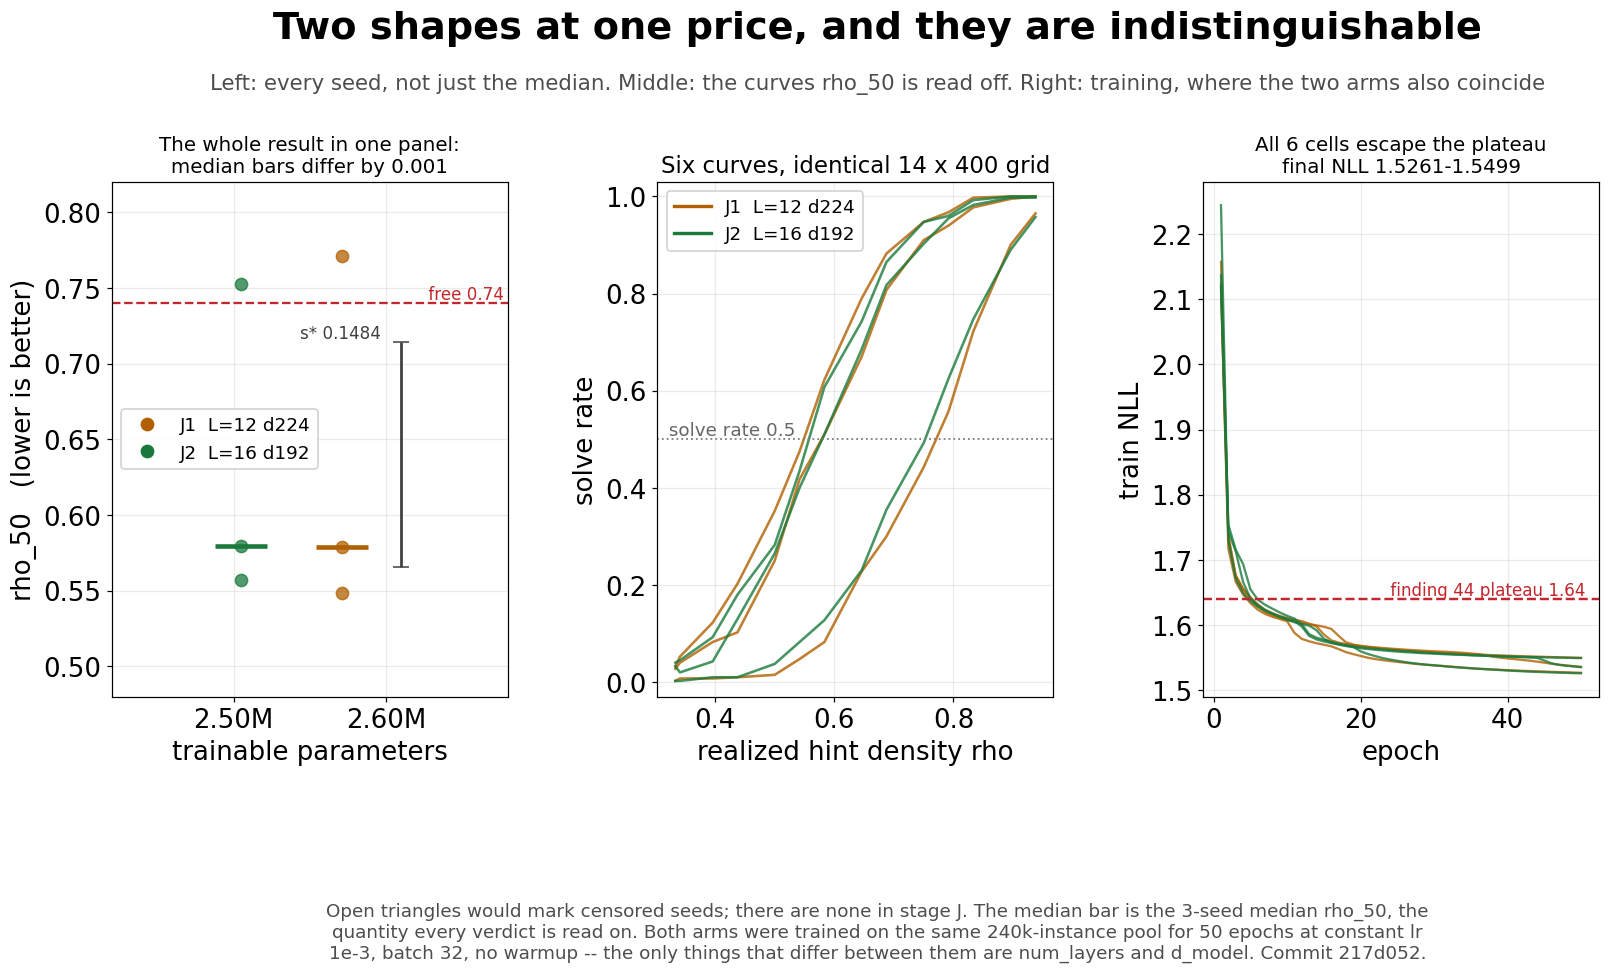

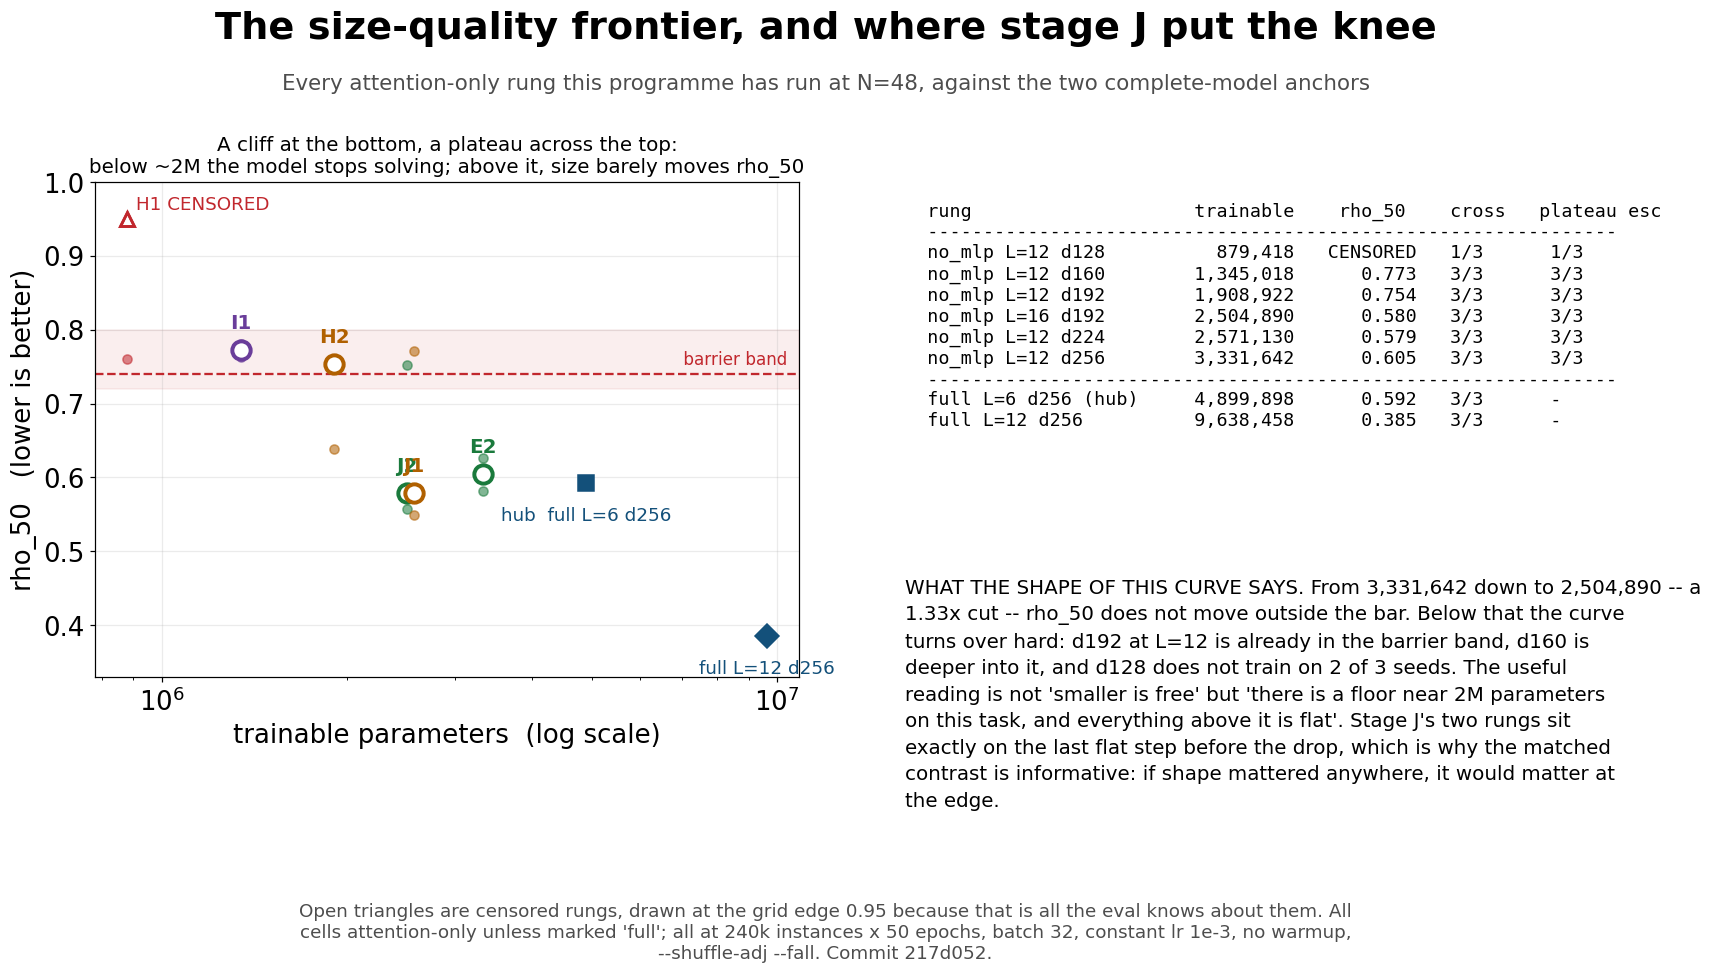

In [5]:
from notebooks.make_stagej_deck import page_contrast, page_frontier
from notebooks.deck_utils import set_style
from scripts.stagec_score import rung as _rung

set_style()
rows = frontier_rows(cells)
anchors = {"hub": dict(s=summarize(_rung(cells, HUB))),
           "best": dict(s=summarize(_rung(cells, FULL_L12)))}


class Keep:
    """A PdfAndPng stand-in that keeps the figure open for the notebook."""

    def savefig(self, fig):
        pass


page_contrast(Keep(), p, raw, COMMIT)
page_frontier(Keep(), rows, anchors, p, COMMIT)

## 5. Does token accuracy still explain a SHAPE change?

The programme's standing result is that a cell's mean solve rate is predicted by
its validation token accuracy alone, through a curve fitted on the **depth
ladder only** (full-width, 4-head, unmodified transformers at L=1..12). Every
test of it so far has been a cut that made the model smaller. Stage J is the
first that changes the model's shape at a fixed size, and the curve was never
fit on anything like it.

The bar is the depth ladder's own leave-one-out residual, `LOO_BAR` = 0.0423:
anything smaller is what a reference cell's own distance from the curve looks
like. Only **well-determined** cells count — ones bracketed by depth cells
closer together than the bar — and among those, the **discriminating** ones are
those the curve sends above a solve rate of 0.10, where landing on the curve is
a real constraint rather than two numbers agreeing near zero.

This is a CORRELATIONAL result about this grid's range. It does not say the
architectures are the same model; it says no cut tried so far has opened a
second, deduction-specific way to fail.

In [6]:
r = subprocess.run([sys.executable, "-m", "scripts.acc_vs_solve", "--scan-dir"] + DIRS,
                   cwd=REPO, capture_output=True, text=True)
tail = r.stdout.strip().split(chr(10))
keep = [l for l in tail if l.strip().startswith(">>>") or "Worst miss" in l
        or "DISCRIMINATING --" in l or "mean residual" in l
        or l.strip().startswith("RMS") or "DETERMINED --" in l]
print(chr(10).join(keep))
print()
suf = sufficiency(DIRS)
print(f"recomputed in-process: {suf['n_exp']}/{suf['n_rungs']} well-determined held-out rungs "
      f"({suf['n_cells']} cells) on the curve,")
print(f"  {suf['n_sharp']} discriminating, worst miss {suf['worst']:.4f} against the "
      f"leave-one-out bar {suf['bar']:.4f}")
print(f"  before stage J this was 21/21 over 46 cells, 20 discriminating, worst 0.0222")
print()
print("  the two new rungs:")
for tag, k in (("J1", J1), ("J2", J2)):
    if k in suf["means"]:
        m = suf["means"][k]
        print(f"    {tag}  mean residual {m:+.4f}   "
              f"{'EXPLAINED by token accuracy' if abs(m) <= suf['bar'] else 'OFF THE CURVE'}")
    else:
        print(f"    {tag}  NOT well-determined -- it lands in the empty stretch of the "
              f"depth ladder,")
        print(f"        where the curve is flat, so it is listed above as weakly "
              f"determined and")
        print(f"        does NOT count toward the {suf['n_exp']}. Agreement there is "
              f"consistency, not evidence.")
print()
print("  So the shape change is tested by J2's rung, not by both: J1 sits where the")
print("  ladder has no nearby cells to bracket it. One well-determined new rung, on")
print("  the curve, is what stage J adds to this result.")

  RMS 0.0423, max |residual| 0.1232 over 21 depth cells
=== per rung, mean residual against the bar 0.0423 ===
  -- WELL-DETERMINED -- bracketed by depth cells closer together than the bar, so these rows carry the result
     L=12 h=4 no_mlp d192       n=2  mean residual +0.0076   EXPLAINED by token accuracy
     L=16 h=4 no_mlp d192       n=1  mean residual +0.0062   EXPLAINED by token accuracy
     L=6  h=4 no_mlp d384       n=2  mean residual +0.0061   EXPLAINED by token accuracy
     L=12 h=4 no_mlp d128       n=2  mean residual +0.0057   EXPLAINED by token accuracy
     L=6  h=4 linear            n=3  mean residual +0.0036   EXPLAINED by token accuracy
     L=6  h=4 full ff256        n=1  mean residual +0.0036   EXPLAINED by token accuracy
     L=12 h=4 no_mlp            n=1  mean residual +0.0004   EXPLAINED by token accuracy
     L=6  h=4 no_mlp            n=2  mean residual +0.0003   EXPLAINED by token accuracy
     L=6  h=4 no_mlp ep100      n=3  mean residual -0.0011   EXPLAI

## 6. `rho_50` before and after, on the same eval

The eval is unchanged — the same 14-point × 400-instance leak-free grid,
`--shuffle-adj --fall` throughout, and the same frozen bar `s*` = 0.1484 /
0.2918, fixed before any of these cells ran and not recomputed here. Both arms
ran 50 epochs on the same 240k pool as every rung they are compared against, so
these comparisons are within budget and legitimate.

**What is claimed:** the minimum is **1.33× smaller at no separable cost**. Not
"better". `rho_50` moved −0.025 = 0.17 `s*`, which is below the separability
bar, so the right reading is that the smaller model costs nothing measurable,
not that it gained anything.

**What is not claimed:** that `L=16 d192` beats `L=12 d224`. They are 0.001
apart and their budgets differ by less than this job's own tolerance, so the
honest statement is **the minimum is ~2,500,000 trainable parameters at either
shape**, and the choice between the two shapes is not a result.

In [7]:
e2 = summarize(_rung(cells, E2))
hub = summarize(_rung(cells, HUB))
l12 = summarize(_rung(cells, FULL_L12))
h2 = summarize(_rung(cells, H2))

print("BEFORE -- the standing minimum and the reference points it is read against")
print(f"  {'rung':<36}{'rho_50':>10}{'mean_solve':>12}{'trainable':>12}")
print("  " + "-" * 70)
for nm, s in (("standing minimum  no_mlp L=12 d256", e2),
              ("same width at L=12  no_mlp d192 (H2)", h2),
              ("hub               full   L=6  d256", hub),
              ("best solver       full   L=12 d256", l12)):
    print(f"  {nm:<36}{rho_txt(s):>10}{s['mean_solve']:>12.4f}{s['trainable']:>12,}")

print()
print("AFTER -- the two stage J arms, same eval, same budget")
print(f"  {'rung':<36}{'rho_50':>10}{'mean_solve':>12}{'trainable':>12}{'vs min':>10}")
print("  " + "-" * 80)
tag0, desc0, tr0, rho0 = STANDING
for t in ("J1", "J2"):
    s = p[t]["s"]
    # Against STANDING's registered 0.605, which is the number the rule was
    # written against -- not against a re-measurement of the same rung, which
    # rounds the other way and would put a digit between this table and the
    # scorer above.
    print(f"  {t + '  no_mlp ' + p[t]['name_short']:<36}{rho_txt(s):>10}"
          f"{s['mean_solve']:>12.4f}{s['trainable']:>12,}"
          f"{s['rho50'] - rho0:>+10.3f}")

print()
new = min((p["J1"]["s"], p["J2"]["s"]), key=lambda s: s["trainable"])
print(f"THE RULE: a rung replaces the standing minimum only if 3 of 3 seeds cross AND")
print(f"median rho_50 <= {FREE}. Both arms satisfy it; the pre-named tie-break is the")
print(f"smaller parameter count.")
print(f"  FROM  {desc0:<26}{tr0:>12,} at {rho0:.3f}")
print(f"  TO    {'attention-only L=16 d192':<26}{new['trainable']:>12,} at {new['rho50']:.3f}")
print(f"  size DOWN {tr0 / new['trainable']:.2f}x, and "
      f"{HUB_TRAINABLE / new['trainable']:.2f}x below the hub "
      f"({HUB_TRAINABLE:,} at {HUB_RHO50:.3f})")
d = new["rho50"] - rho0
print(f"  rho_50 moves {d:+.3f} = {abs(d) / S_RHO50:.2f} s*, "
      f"{'BELOW' if abs(d) <= S_RHO50 else 'ABOVE'} the separability bar")
print()
print("DEPTH PAST L=12, the other half of the move (J2 against the same width at L=12):")
# PRED_J2_BELOW is H2 as the prediction was registered against it; the scorer
# reads the gap off that constant, so this does too.
print(f"  H2  no_mlp L=12 d192   {PRED_J2_BELOW:.3f}   (as registered; "
      f"re-measured here at {h2['rho50']:.4f})")
print(f"  J2  no_mlp L=16 d192   {p['J2']['s']['rho50']:.3f}   "
      f"{p['J2']['s']['rho50'] - PRED_J2_BELOW:+.3f} = "
      f"{abs(p['J2']['s']['rho50'] - PRED_J2_BELOW) / S_RHO50:.2f} s*, separable")
print(f"  the depth evidence this extrapolated from stopped at L=12: "
      + ", ".join(f"L={k} {v}" for k, v in sorted(DEPTH_EVIDENCE.items())))

BEFORE -- the standing minimum and the reference points it is read against
  rung                                    rho_50  mean_solve   trainable
  ----------------------------------------------------------------------
  standing minimum  no_mlp L=12 d256       0.605      0.5214   3,331,642
  same width at L=12  no_mlp d192 (H2)     0.754      0.3220   1,908,922
  hub               full   L=6  d256       0.592      0.5389   4,899,898
  best solver       full   L=12 d256       0.385      0.8163   9,638,458

AFTER -- the two stage J arms, same eval, same budget
  rung                                    rho_50  mean_solve   trainable    vs min
  --------------------------------------------------------------------------------
  J1  no_mlp L=12 d224                     0.579      0.5521   2,571,130    -0.026
  J2  no_mlp L=16 d192                     0.580      0.5527   2,504,890    -0.025

THE RULE: a rung replaces the standing minimum only if 3 of 3 seeds cross AND
median rho_50 <= 0.74

## 7. What this does not settle, and what is running

**The N=48 ladder is closed, and the closing argument is J0.** There is no
further architecture cut this grid can resolve. Width below `d192` does not
train (stage H), the `d160`–`d192` stretch buys nothing a seed could not (stage
I), and stage J has now shown that trading depth against width at a fixed
budget changes nothing measurable. What is left to vary is size, and the
frontier is flat from ~2.5M up to the hub's 4,899,898 and falls off a cliff
below. The useful reading is not "smaller is free" but **"there is a floor near
2M parameters on this task, and everything above it is flat"**.

**The open N=48 question is J1's, and it is deliberately not being chased
now.** The width curve is convex on [192, 256]: all three interpolations
overestimated `rho_50` at `d224`. A fourth width point is the only way to know
the shape of that stretch, and it is NOT bundled into stage F, which changes the
problem size and must change nothing else.

**`51656823` stage F** is in flight: the surviving architecture at **N=96**
against a PAIRED complete-model control — 4 cells, 36.5 GPU-h, cheap only
because the control already exists (8 N=96 cells trained leak-free at the same
240k × 50 budget on the identical 14 × 400 grid, `full L=12 d256` → 0.621 over
two seeds). F buys the stripped arm at 3 seeds plus the missing THIRD control
seed. Registered: `|stripped − control| ≤ s*_96 = 0.119`, frozen from the three
two-seed N=96 rungs that exist today. **`s*` = 0.1484 is an N=48 number and is
not reused there**, and neither is finding 44's 1.64 plateau — N=96's own
plateau has never been measured, so no escape count will be quoted for F.

**The falsifier that matters, stated before F's numbers arrive:** if the
stripped arm comes back HIGHER than the N=96 control by more than 0.119, the
N=48 minimum does not transfer and every "smallest architecture" claim in this
programme gets relabelled as an N=48 claim. That is a real possible outcome, not
a formality. If any of the three stripped seeds CENSORS, the breaking point is
the result and it becomes the headline.